# Week 6: Week types (K-means + PCA)

Goal: group your weeks into a few **types** (for example *Big shopping week* or *Quiet week*) with **K-means**, then draw them in 2D with **PCA**. You name the types; the app then tells you which type this week looks like.

This is **unsupervised** learning: there are no labels to score against. You judge clusters by how separated they are (silhouette) and by whether they mean something.

Spec: `docs/superpowers/specs/2026-10-23-week-types-design.md`. Data: `data/fake_transactions_3y.csv` (from Week 5).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

CATEGORIES = ['Food & Drinks', 'Coffee & Snacks', 'Groceries', 'Transportation', 'Bills & Utilities',
              'Shopping', 'Healthcare', 'Entertainment']
FEATURES = [f'share_{c}' for c in CATEGORIES] + ['total_ratio']   # the app builds exactly these, in this order

df = pd.read_csv('../data/fake_transactions_3y.csv')
exp = df[df['Type'] == 'expense'].copy()
exp['day'] = pd.to_datetime(exp['Date']).dt.tz_localize(None).dt.normalize()
exp['week'] = exp['day'].dt.to_period('W-SUN')   # weeks start on Monday

# Whole weeks only: the file starts and ends mid-week
FIRST_WEEK, LAST_WEEK = exp['week'].min() + 1, exp['week'].max() - 1
print(FIRST_WEEK, '→', LAST_WEEK)

2023-10-23/2023-10-29 → 2026-10-12/2026-10-18


---
## A. Weekly table
One row per week (every week from `FIRST_WEEK` to `LAST_WEEK`, empty weeks = 0), one column per category in `CATEGORIES` order. Save it as `weekly`, and the week totals as `total`.

Hints: `pivot_table(index='week', columns='Category', values='Amount', aggfunc='sum', fill_value=0)`, then `reindex(pd.period_range(FIRST_WEEK, LAST_WEEK, freq='W-SUN'), fill_value=0)` and `reindex(columns=CATEGORIES, fill_value=0)`.

In [2]:
# TODO
weekly = exp.pivot_table(index='week', columns='Category', values='Amount',
                         aggfunc='sum', fill_value=0)
weekly = weekly.reindex(pd.period_range(FIRST_WEEK, LAST_WEEK, freq='W-SUN'), fill_value=0)
weekly = weekly.reindex(columns=CATEGORIES, fill_value=0)
weekly.index.name = 'week'
weekly.columns.name = None

total = weekly.sum(axis=1)

# Checks
assert len(weekly) == (LAST_WEEK - FIRST_WEEK).n + 1     # every week present
assert list(weekly.columns) == CATEGORIES
print(weekly.shape, f'empty weeks: {(total == 0).sum()}')
weekly.tail()

(156, 8) empty weeks: 0


,Food & Drinks,Coffee & Snacks,Groceries,Transportation,Bills & Utilities,Shopping,Healthcare,Entertainment
week,,,,,,,,
2026-09-14/2026-09-20,2317.44,881.89,7063.67,5021.45,0.00,10392.09,2306.51,0.00
2026-09-21/2026-09-27,3592.12,695.99,746.42,4384.71,0.00,4765.11,1278.64,0.00
2026-09-28/2026-10-04,3386.13,655.11,1688.79,6841.79,0.00,3321.80,1395.87,0.00
2026-10-05/2026-10-11,2432.19,2396.24,14283.73,3680.57,8038.83,4632.70,0.00,0.00
2026-10-12/2026-10-18,3917.00,1112.63,3791.10,5367.51,0.00,6680.68,803.95,296.19


---
## B. Features
For each week, 9 numbers. Save them as a DataFrame `X` with columns `FEATURES`:
- `share_<category>`: that category's total ÷ the week's total (the 8 shares add up to 1). Hint: `weekly.div(total, axis=0).add_prefix('share_')`
- `total_ratio`: the week's total ÷ the **median of the weeks before it** (up to 8, at least 4). Hint: `total.shift().rolling(8, min_periods=4).median()`. `shift()` keeps the week itself out: no look-ahead.

Drop weeks with a total of 0 or without a ratio (`replace([np.inf, -np.inf], np.nan).dropna()`).

**Think:** why shares and a ratio instead of pesos? (Hint: the app will use these centres for real users who spend more or less than the fake data.)

In [3]:
# TODO
shares = weekly.div(total, axis=0).add_prefix('share_')       # 0/0 → NaN for empty weeks
usual_week = total.shift().rolling(8, min_periods=4).median()  # earlier weeks only

X = shares.assign(total_ratio=total / usual_week)[FEATURES]
X = X.replace([np.inf, -np.inf], np.nan).dropna()

# Checks
assert list(X.columns) == FEATURES
assert np.allclose(X.filter(like='share_').sum(axis=1), 1)
assert (X['total_ratio'] > 0).all()
print(X.shape, f'(dropped {len(weekly) - len(X)} weeks)')
X.describe().round(2)

(152, 9) (dropped 4 weeks)


,share_Food & Drinks,share_Coffee & Snacks,share_Groceries,share_Transportation,share_Bills & Utilities,share_Shopping,share_Healthcare,share_Entertainment,total_ratio
count,152.00,152.00,152.00,152.00,152.00,152.00,152.00,152.00,152.00
mean,0.19,0.04,0.23,0.20,0.07,0.18,0.04,0.05,1.06
std,0.07,0.02,0.14,0.08,0.12,0.15,0.07,0.07,0.37
min,0.07,0.01,0.00,0.05,0.00,0.00,0.00,0.00,0.38
25%,0.14,0.03,0.13,0.14,0.00,0.06,0.00,0.00,0.78
50%,0.17,0.03,0.21,0.18,0.00,0.15,0.00,0.02,1.03
75%,0.24,0.05,0.35,0.24,0.00,0.28,0.07,0.09,1.23
max,0.39,0.11,0.57,0.48,0.43,0.66,0.33,0.37,2.39


This check recomputes one week straight from the raw expenses. If it passes, the features are right and there is no look-ahead.

In [4]:
w = X.index[len(X) // 2]
rows = exp[exp['week'] == w]
assert abs(X.loc[w, 'share_Groceries'] - rows.loc[rows['Category'] == 'Groceries', 'Amount'].sum() / rows['Amount'].sum()) < 1e-9
before = [exp.loc[exp['week'] == w - k, 'Amount'].sum() for k in range(1, 9)]
assert abs(X.loc[w, 'total_ratio'] - rows['Amount'].sum() / np.median(before)) < 1e-9
assert list(X.columns[:9]) == FEATURES
print(len(X), 'weeks ✓')

152 weeks ✓


---
## C. Scale
Fit a `StandardScaler` on `X[FEATURES]` (save it as `scaler`) and make `Xs = scaler.transform(X[FEATURES])`.

**Think:** K-means measures plain distance. What would happen without scaling, when `total_ratio` swings between 0.3 and 3 but a small share moves between 0.00 and 0.05?

In [5]:
# TODO
scaler = StandardScaler().fit(X[FEATURES])
Xs = scaler.transform(X[FEATURES])

# Check: every column now has mean ≈ 0 and std ≈ 1
assert np.allclose(Xs.mean(axis=0), 0, atol=1e-9)
assert np.allclose(Xs.std(axis=0), 1, atol=1e-9)
print(Xs.shape)

(152, 9)


---
## D. Choose k
For k = 2…8, fit `KMeans(k, n_init=10, random_state=0)` on `Xs` and record `inertia_` and `silhouette_score(Xs, labels_)`. Plot both against k.

- **Elbow:** where adding clusters stops helping much
- **Silhouette:** −1…1, higher = better separated

**Think:** if the silhouette is only ~0.2 for every k, what does that tell you about spending? Is that a reason not to use clusters?

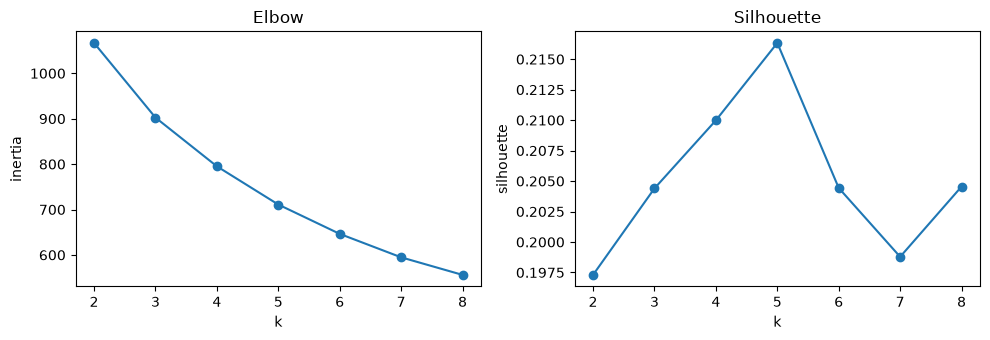

,inertia,silhouette,smallest
k,,,
2,1066.873,0.197,66
3,902.499,0.204,35
4,795.131,0.210,26
5,710.936,0.216,12
6,646.332,0.204,7
7,594.705,0.199,10
8,556.005,0.205,7


In [6]:
# TODO
ks = range(2, 9)
rows = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Xs)
    rows.append({'k': k,
                 'inertia': km.inertia_,
                 'silhouette': silhouette_score(Xs, km.labels_),
                 'smallest': np.bincount(km.labels_).min()})
k_scores = pd.DataFrame(rows).set_index('k')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(k_scores.index, k_scores['inertia'], marker='o')
ax1.set(title='Elbow', xlabel='k', ylabel='inertia')
ax2.plot(k_scores.index, k_scores['silhouette'], marker='o')
ax2.set(title='Silhouette', xlabel='k', ylabel='silhouette')
plt.tight_layout(); plt.show()

k_scores.round(3)

Set `K` to your choice and write one sentence why below it.

In [10]:
K = 5
# Highest silhouette (0.216, up from 0.210 at k=4, down to 0.204 at k=6); smallest cluster
# still has 12 weeks; no clear elbow, so the silhouette peak decides.

---
## E. Read the clusters
Fit the final `km = KMeans(K, n_init=10, random_state=0)` on `Xs`, add `X['cluster'] = km.labels_`, and show:
1. how many weeks each cluster has
2. the mean of each feature per cluster (unscaled: `X.groupby('cluster')[FEATURES].mean()`)

In [11]:
# TODO
km = KMeans(K, n_init=10, random_state=0).fit(Xs)
X['cluster'] = km.labels_

# 1. Weeks per cluster
print(X['cluster'].value_counts().sort_index().to_string(), '\n')

# 2. Mean of each feature per cluster, with the overall mean for comparison
profile = X.groupby('cluster')[FEATURES].mean()
profile.loc['all weeks'] = X[FEATURES].mean()
profile.round(2)

cluster
0    32
1    35
2    47
3    12
4    26 



,share_Food & Drinks,share_Coffee & Snacks,share_Groceries,share_Transportation,share_Bills & Utilities,share_Shopping,share_Healthcare,share_Entertainment,total_ratio
cluster,,,,,,,,,
0,0.15,0.03,0.20,0.15,0.29,0.12,0.04,0.02,1.41
1,0.15,0.03,0.20,0.15,0.01,0.40,0.03,0.03,1.22
2,0.20,0.04,0.37,0.23,0.00,0.10,0.02,0.04,0.88
3,0.18,0.03,0.13,0.18,0.02,0.16,0.04,0.24,1.07
4,0.27,0.06,0.09,0.28,0.00,0.14,0.11,0.05,0.72
all weeks,0.19,0.04,0.23,0.20,0.07,0.18,0.04,0.05,1.06


And the 3 real weeks nearest each centre (`km.transform(Xs)` gives distances). Look at what happened in those weeks.

In [12]:
# TODO
dist = km.transform(Xs)                     # distance from each week to each centre

for c in range(K):
    nearest = np.argsort(dist[:, c])[:3]    # positions of the 3 closest weeks
    weeks_c = X.index[nearest]
    print(f'\n=== Cluster {c} ({(X["cluster"] == c).sum()} weeks) ===')
    show = weekly.loc[weeks_c].round(0)
    show['total'] = total.loc[weeks_c].round(0)
    show['total_ratio'] = X.loc[weeks_c, 'total_ratio'].round(2)
    print(show.to_string())


=== Cluster 0 (32 weeks) ===
                       Food & Drinks  Coffee & Snacks  Groceries  Transportation  Bills & Utilities  Shopping  Healthcare  Entertainment    total  total_ratio
week                                                                                                                                                          
2025-11-03/2025-11-09         3373.0            568.0     5219.0          4050.0             7855.0    3995.0       280.0         2052.0  27391.0         1.63
2026-03-30/2026-04-05         2712.0            691.0     4746.0          3881.0             8378.0    4995.0         0.0            0.0  25402.0         1.20
2024-07-01/2024-07-07         3933.0            891.0     3586.0          3732.0             6666.0    5726.0      1922.0         1940.0  28397.0         1.53

=== Cluster 1 (35 weeks) ===
                       Food & Drinks  Coffee & Snacks  Groceries  Transportation  Bills & Utilities  Shopping  Healthcare  Entertainment    total

Now **name the types**: one entry per cluster, **in cluster order** (0, 1, 2…). Each `name` ends in "week" (Ollie says *"So far this looks like a {name}."*), `description` is one short sentence, and `pose` is `'happy'`, `'thinking'` or `'celebrating'` (how should Ollie feel about that kind of week?).

In [28]:
TYPES = [
      {'name': 'Bills week',
       'description': 'Most of the spending went to bills and utilities.',
       'pose': 'thinking'},
      {'name': 'Big shopping week',
       'description': 'Shopping took a much bigger share than usual.',
       'pose': 'thinking'},
      {'name': 'Grocery run week',
       'description': 'Groceries made up a big part of the week.',
       'pose': 'happy'},
      {'name': 'Fun week',
       'description': 'A lot more went to movies, games and going out than usual.',
       'pose': 'happy'},
      {'name': 'Out-and-about week',
       'description': 'Mostly eating out and getting around, and below your usual week.',
       'pose': 'celebrating'},
  ]
 

---
## F. PCA: see it in 2D
9 features can't be drawn. PCA finds the 2 directions with the most variation.
- `pca = PCA(2).fit(Xs)`, `P = pca.transform(Xs)`, and the centres `pca.transform(km.cluster_centers_)`
- Scatter `P`, coloured by cluster and labelled with your type names; mark the centres
- Put `pca.explained_variance_ratio_` in the axis labels
- Show the **loadings**: `pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1', 'PC2'])`

**Think:** read the loadings. What does a week far to the right on PC1 look like? And high on PC2? PCA is only for the picture: K-means used all 9 features.

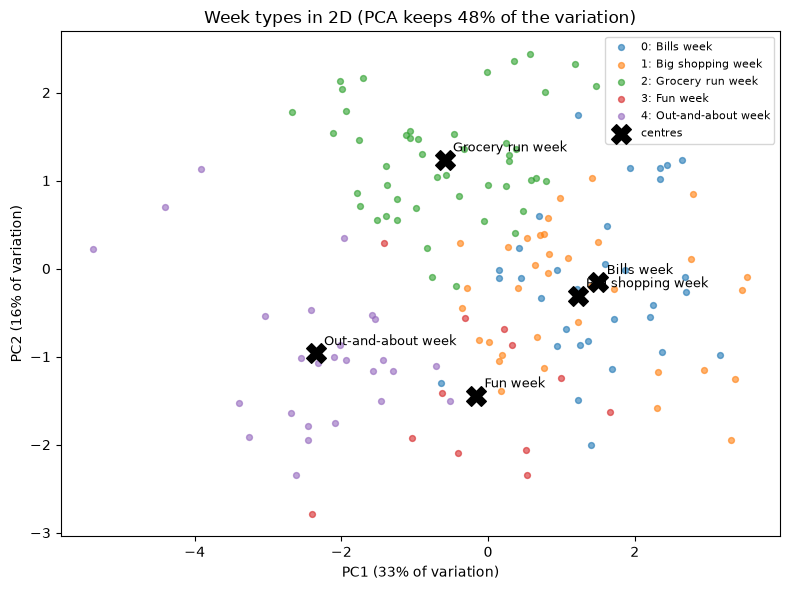

,PC1,PC2
share_Food & Drinks,-0.45,-0.02
share_Coffee & Snacks,-0.40,0.00
share_Groceries,0.10,0.77
share_Transportation,-0.44,0.05
share_Bills & Utilities,0.26,-0.11
share_Shopping,0.30,-0.27
share_Healthcare,-0.16,-0.42
share_Entertainment,-0.06,-0.37
total_ratio,0.50,-0.08


In [29]:
# TODO
pca = PCA(2).fit(Xs)
P = pca.transform(Xs)
C = pca.transform(km.cluster_centers_)
ev = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    m = X['cluster'].to_numpy() == c
    ax.scatter(P[m, 0], P[m, 1], s=18, alpha=0.6, label=f'{c}: {TYPES[c]["name"]}')
ax.scatter(C[:, 0], C[:, 1], marker='X', s=200, c='black', label='centres')
for c, (x, y) in enumerate(C):
    ax.annotate(TYPES[c]['name'], (x, y), xytext=(6, 6), textcoords='offset points', fontsize=9)
ax.set(xlabel=f'PC1 ({ev[0]:.0%} of variation)',
       ylabel=f'PC2 ({ev[1]:.0%} of variation)',
       title=f'Week types in 2D (PCA keeps {ev.sum():.0%} of the variation)')
ax.legend(fontsize=8, loc='best')
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1', 'PC2'])
loadings.round(2)

**What PC1 and PC2 mean:**
  - **PC1 (33% of variation): how big and "one-off" the week is.** The largest loading is `total_ratio` (+0.50), with Shopping (+0.30) and Bills & Utilities (+0.26) on the
  same side. Food & Drinks (−0.45), Transportation (−0.44) and Coffee & Snacks (−0.40) pull the other way. A week far to the right costs more than usual because of a bill or
  a big purchase; a week far to the left is a cheaper everyday week of meals, snacks and getting around.
  - **PC2 (16% of variation): groceries vs. extras.** Groceries dominates the top (+0.77); Healthcare (−0.42) and Entertainment (−0.37) pull to the bottom. High weeks are
  grocery runs; low weeks went to the pharmacy or to going out, which is where the Fun week cluster sits.
  - Bills week and Big shopping week overlap in this view because PC1 treats both as "one big cost". K-means still separates them using all 9 features, where their Bills and
  Shopping shares are very different.

---
## G. Export (given)
Writes `models/week_types.json` for the app: the scaler, the centres, your names, and 3 sample weeks the app must classify the same way.

In [30]:
assert len(TYPES) == K, 'one TYPES entry per cluster'
for t in TYPES:
    assert t['name'].endswith('week') and t['description'] and t['pose'] in ('happy', 'thinking', 'celebrating'), t

dist = km.transform(Xs)
samples = []
for c in range(min(3, K)):
    i = int(dist[:, c].argmin())
    assert km.labels_[i] == c
    samples.append({'week': str(X.index[i].start_time.date()), 'features': X[FEATURES].iloc[i].tolist(), 'type': f't{c}'})

model = {'features': FEATURES, 'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist(),
         'centers': km.cluster_centers_.tolist(),
         'types': [{'id': f't{i}', **t} for i, t in enumerate(TYPES)], 'samples': samples}
Path('../models').mkdir(exist_ok=True)
Path('../models/week_types.json').write_text(json.dumps(model, indent=1))
print('saved models/week_types.json ✓  (copy it to budgettracker/mobile/src/lib/week-types.json)')

saved models/week_types.json ✓  (copy it to budgettracker/mobile/src/lib/week-types.json)
